<a href="https://colab.research.google.com/github/ayubsaid/comp1818-sentiment-analysis/blob/main/sentiment_coursework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP1818 Coursework: Symbolic vs Machine Learning vs Hybrid Sentiment Analysis of Reviews


In [1]:
!pip install -q vaderSentiment datasets statsmodels transformers

In [2]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from datasets import load_dataset
from scipy.sparse import hstack, csr_matrix
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.contingency_tables import mcnemar
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore", category=FutureWarning)
matplotlib.rcParams["pdf.fonttype"] = 42

SEED = 42
np.random.seed(SEED)
RUN_TRANSFORMER = True
TRANSFORMER_N = 500
os.makedirs("outputs", exist_ok=True)

In [3]:
imdb = load_dataset("stanfordnlp/imdb")
train_df, test_df = pd.DataFrame(imdb["train"]), pd.DataFrame(imdb["test"])
X_train, y_train = train_df["text"], train_df["label"].values
X_test, y_test = test_df["text"], test_df["label"].values

yelp_full = load_dataset("fancyzhx/yelp_polarity", split="test").shuffle(seed=SEED)
yelp1, yelp2 = yelp_full.select(range(10000)), yelp_full.select(range(10000, 20000))
Y1_text, y_y1 = pd.Series(yelp1["text"]), np.array(yelp1["label"])
Y2_text, y_y2 = pd.Series(yelp2["text"]), np.array(yelp2["label"])

print("IMDb train/test:", X_train.shape[0], X_test.shape[0], np.bincount(y_train), np.bincount(y_test))
print("Yelp-1 / Yelp-2:", len(y_y1), len(y_y2), np.bincount(y_y1), np.bincount(y_y2))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (8 outputs left out)

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/560000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/38000 [00:00<?, ? examples/s]

IMDb train/test: 25000 25000 [12500 12500] [12500 12500]
Yelp-1 / Yelp-2: 10000 10000 [5016 4984] [4995 5005]


In [4]:
results = {}

def evaluate(name, y_true, y_pred, verbose=True):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    results[name] = {"Accuracy": acc, "Macro-F1": f1}
    if verbose:
        print(f"{name:34s} Accuracy={acc:.4f}  Macro-F1={f1:.4f}")

majority = pd.Series(y_train).mode()[0]
rng = np.random.default_rng(SEED)
evaluate("IMDb | Majority class", y_test, np.full(len(y_test), majority))
evaluate("IMDb | Random guess", y_test, rng.integers(0, 2, size=len(y_test)))
evaluate("Yelp-1 | Majority class", y_y1, np.full(len(y_y1), majority))
evaluate("Yelp-1 | Random guess", y_y1, rng.integers(0, 2, size=len(y_y1)))

IMDb | Majority class              Accuracy=0.5000  Macro-F1=0.3333
IMDb | Random guess                Accuracy=0.5026  Macro-F1=0.5026
Yelp-1 | Majority class            Accuracy=0.5016  Macro-F1=0.3340
Yelp-1 | Random guess              Accuracy=0.5039  Macro-F1=0.5039


In [5]:
analyzer = SentimentIntensityAnalyzer()

def vader_features(texts):
    return np.array([[s["neg"], s["neu"], s["pos"], s["compound"]]
                     for s in (analyzer.polarity_scores(t) for t in texts)])

def cached_vader(name, texts):
    path = f"outputs/vader_{name}.npy"
    if os.path.exists(path):
        return np.load(path)
    t0 = time.time()
    arr = vader_features(texts)
    np.save(path, arr)
    print(f"  scored {name}: {len(texts)} reviews in {time.time() - t0:.0f}s")
    return arr

V_train = cached_vader("imdb_train", X_train)
V_test = cached_vader("imdb_test", X_test)
V_y1 = cached_vader("yelp1", Y1_text)
V_y2 = cached_vader("yelp2", Y2_text)
print(V_train.shape, V_test.shape, V_y1.shape, V_y2.shape)

  scored imdb_train: 25000 reviews in 154s
  scored imdb_test: 25000 reviews in 95s
  scored yelp1: 10000 reviews in 14s
  scored yelp2: 10000 reviews in 16s
(25000, 4) (25000, 4) (10000, 4) (10000, 4)


In [6]:
evaluate("IMDb | VADER (threshold 0)", y_test, (V_test[:, 3] >= 0).astype(int))
print(confusion_matrix(y_test, (V_test[:, 3] >= 0).astype(int)))

IMDb | VADER (threshold 0)         Accuracy=0.6973  Macro-F1=0.6886
[[ 6634  5866]
 [ 1702 10798]]


Best threshold on validation data: 0.80


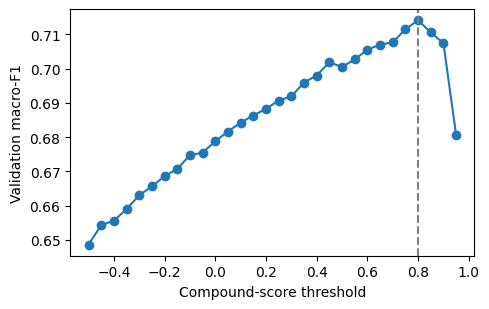

IMDb | VADER (tuned)               Accuracy=0.7258  Macro-F1=0.7257
[[8806 3694]
 [3160 9340]]


In [7]:
idx_tr, idx_val = train_test_split(np.arange(len(y_train)), test_size=0.2,
                                   stratify=y_train, random_state=SEED)
thresholds = np.arange(-0.5, 0.96, 0.05)
val_f1 = [f1_score(y_train[idx_val], (V_train[idx_val, 3] >= t).astype(int), average="macro")
          for t in thresholds]
best_t = float(thresholds[int(np.argmax(val_f1))])
print(f"Best threshold on validation data: {best_t:.2f}")

plt.figure(figsize=(5, 3.2))
plt.plot(thresholds, val_f1, marker="o")
plt.axvline(best_t, linestyle="--", color="gray")
plt.xlabel("Compound-score threshold")
plt.ylabel("Validation macro-F1")
plt.tight_layout()
plt.savefig("outputs/vader_threshold.pdf")
plt.show()

tuned_pred = (V_test[:, 3] >= best_t).astype(int)
evaluate("IMDb | VADER (tuned)", y_test, tuned_pred)
print(confusion_matrix(y_test, tuned_pred))

In [8]:
tfidf0 = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True, min_df=2)
Xtr0 = tfidf0.fit_transform(X_train)
Xte0 = tfidf0.transform(X_test)
lr0 = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED).fit(Xtr0, y_train)
evaluate("IMDb | TF-IDF + LR (default)", y_test, lr0.predict(Xte0))

IMDb | TF-IDF + LR (default)       Accuracy=0.9007  Macro-F1=0.9007


In [9]:

grid = GridSearchCV(LogisticRegression(max_iter=1000, random_state=SEED),
                    {"C": [0.1, 1, 10, 100]}, cv=3, scoring="f1_macro", n_jobs=-1)
grid.fit(Xtr0, y_train)
print(pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score"]])
best_C = grid.best_params_["C"]
print("Best C:", best_C)


cv_scores = {}
for ng in [(1, 1), (1, 2)]:
    vec = TfidfVectorizer(max_features=50000, ngram_range=ng, sublinear_tf=True, min_df=2)
    A = vec.fit_transform(X_train)
    cv_scores[ng] = cross_val_score(LogisticRegression(C=best_C, max_iter=1000, random_state=SEED),
                                    A, y_train, cv=3, scoring="f1_macro").mean()
    print(ng, round(cv_scores[ng], 4))
best_ng = max(cv_scores, key=cv_scores.get)
print("Best n-gram range:", best_ng)


tfidf = TfidfVectorizer(max_features=50000, ngram_range=best_ng, sublinear_tf=True, min_df=2)
Xtr, Xte = tfidf.fit_transform(X_train), tfidf.transform(X_test)
lr_best = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED).fit(Xtr, y_train)
lr_pred = lr_best.predict(Xte)
evaluate("IMDb | TF-IDF + LR (tuned)", y_test, lr_pred)

   param_C  mean_test_score
0      0.1         0.855730
1      1.0         0.883340
2     10.0         0.883448
3    100.0         0.879729
Best C: 10
(1, 1) 0.8625
(1, 2) 0.8834
Best n-gram range: (1, 2)
IMDb | TF-IDF + LR (tuned)         Accuracy=0.9023  Macro-F1=0.9023


In [10]:

Htr = hstack([Xtr, csr_matrix(V_train)]).tocsr()
Hte = hstack([Xte, csr_matrix(V_test)]).tocsr()
hyb = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED).fit(Htr, y_train)
hyb_pred = hyb.predict(Hte)
evaluate("IMDb | Hybrid (feature-level)", y_test, hyb_pred)


base = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
oof = cross_val_predict(base, Xtr, y_train, cv=5, method="predict_proba", n_jobs=-1)[:, 1]
S_train = np.column_stack([oof, V_train[:, 3]])
S_test = np.column_stack([lr_best.predict_proba(Xte)[:, 1], V_test[:, 3]])
meta = LogisticRegression(random_state=SEED).fit(S_train, y_train)
stack_pred = meta.predict(S_test)
print("Meta weights [LR prob, VADER compound]:", meta.coef_, meta.intercept_)
evaluate("IMDb | Hybrid (stacking)", y_test, stack_pred)

IMDb | Hybrid (feature-level)      Accuracy=0.9015  Macro-F1=0.9015
Meta weights [LR prob, VADER compound]: [[6.67134505 0.37585192]] [-3.40329696]
IMDb | Hybrid (stacking)           Accuracy=0.9030  Macro-F1=0.9030


In [11]:
def yelp_eval(tag, text, y, V):
    X = tfidf.transform(text)
    H = hstack([X, csr_matrix(V)]).tocsr()
    S = np.column_stack([lr_best.predict_proba(X)[:, 1], V[:, 3]])
    p = {"VADER (tuned)": (V[:, 3] >= best_t).astype(int),
         "TF-IDF + LR (tuned)": lr_best.predict(X),
         "Hybrid (feature-level)": hyb.predict(H),
         "Hybrid (stacking)": meta.predict(S)}
    for name, pred in p.items():
        evaluate(f"{tag} | {name}", y, pred)
    return p, X, H

y1_preds, Xy1, Hy1 = yelp_eval("Yelp-1", Y1_text, y_y1, V_y1)
print()
y2_preds, Xy2, Hy2 = yelp_eval("Yelp-2", Y2_text, y_y2, V_y2)
print("\nMean words/review  IMDb:", round(X_test.str.split().str.len().mean(), 1),
      " Yelp-1:", round(Y1_text.str.split().str.len().mean(), 1))

Yelp-1 | VADER (tuned)             Accuracy=0.7753  Macro-F1=0.7748
Yelp-1 | TF-IDF + LR (tuned)       Accuracy=0.8444  Macro-F1=0.8438
Yelp-1 | Hybrid (feature-level)    Accuracy=0.8668  Macro-F1=0.8664
Yelp-1 | Hybrid (stacking)         Accuracy=0.8455  Macro-F1=0.8448

Yelp-2 | VADER (tuned)             Accuracy=0.7719  Macro-F1=0.7713
Yelp-2 | TF-IDF + LR (tuned)       Accuracy=0.8458  Macro-F1=0.8452
Yelp-2 | Hybrid (feature-level)    Accuracy=0.8665  Macro-F1=0.8662
Yelp-2 | Hybrid (stacking)         Accuracy=0.8469  Macro-F1=0.8462

Mean words/review  IMDb: 228.5  Yelp-1: 130.3


In [12]:
def mcnemar_test(a, b, y):
    ca, cb = (a == y), (b == y)
    n_a_only, n_b_only = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
    table = [[int(np.sum(ca & cb)), n_a_only], [n_b_only, int(np.sum(~ca & ~cb))]]
    return n_a_only, n_b_only, mcnemar(table, exact=True).pvalue

pairs = [("TF-IDF + LR (tuned)", "VADER (tuned)"),
         ("TF-IDF + LR (tuned)", "Hybrid (feature-level)"),
         ("TF-IDF + LR (tuned)", "Hybrid (stacking)"),
         ("Hybrid (stacking)", "Hybrid (feature-level)")]
imdb_preds = {"VADER (tuned)": tuned_pred, "TF-IDF + LR (tuned)": lr_pred,
              "Hybrid (feature-level)": hyb_pred, "Hybrid (stacking)": stack_pred}

mc_rows = []
for tag, P, y in [("IMDb", imdb_preds, y_test), ("Yelp-1", y1_preds, y_y1), ("Yelp-2", y2_preds, y_y2)]:
    for a, b in pairs:
        na, nb, p = mcnemar_test(P[a], P[b], y)
        mc_rows.append({"Test set": tag, "Model A": a, "Model B": b,
                        "Only A right": na, "Only B right": nb, "p-value": p})
mc = pd.DataFrame(mc_rows)
mc.to_csv("outputs/mcnemar_results.csv", index=False)
print(mc.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print("\n(p printed as 0 means p < 1e-300; report as p < 0.001)")

Test set             Model A                Model B  Only A right  Only B right   p-value
    IMDb TF-IDF + LR (tuned)          VADER (tuned)          5549          1138         0
    IMDb TF-IDF + LR (tuned) Hybrid (feature-level)           393           374    0.5158
    IMDb TF-IDF + LR (tuned)      Hybrid (stacking)           161           180    0.3297
    IMDb   Hybrid (stacking) Hybrid (feature-level)           338           300    0.1429
  Yelp-1 TF-IDF + LR (tuned)          VADER (tuned)          1623           932 6.229e-43
  Yelp-1 TF-IDF + LR (tuned) Hybrid (feature-level)           207           431 4.598e-19
  Yelp-1 TF-IDF + LR (tuned)      Hybrid (stacking)            81            92    0.4472
  Yelp-1   Hybrid (stacking) Hybrid (feature-level)           183           396 4.984e-19
  Yelp-2 TF-IDF + LR (tuned)          VADER (tuned)          1618           879 4.485e-50
  Yelp-2 TF-IDF + LR (tuned) Hybrid (feature-level)           218           425 2.507e-16
  Yelp-2 T

      TF-IDF + LR         Hybrid (feature-level)        
             mean     std                   mean     std
n                                                       
100        0.6888  0.0230                 0.7240  0.0218
500        0.8083  0.0106                 0.7800  0.0204
2000       0.8632  0.0048                 0.8353  0.0017
10000      0.8914  0.0019                 0.8868  0.0016
25000      0.9023     NaN                 0.9006     NaN


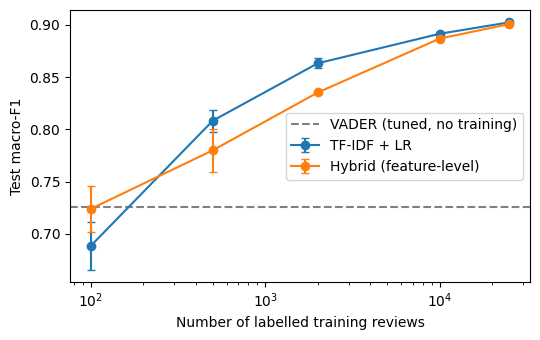

In [13]:
sizes = [100, 500, 2000, 10000, 25000]
rows = []
for n in sizes:
    for s in [0, 1, 2]:
        if n == len(y_train) and s > 0:
            continue
        idx = np.random.default_rng(s).choice(len(y_train), size=n, replace=False)
        vec = TfidfVectorizer(max_features=50000, ngram_range=best_ng, sublinear_tf=True, min_df=2)
        A = vec.fit_transform(X_train.iloc[idx])
        B = vec.transform(X_test)
        m1 = LogisticRegression(C=best_C, max_iter=1000).fit(A, y_train[idx])
        f_lr = f1_score(y_test, m1.predict(B), average="macro")
        m2 = LogisticRegression(C=best_C, max_iter=1000).fit(
            hstack([A, csr_matrix(V_train[idx])]).tocsr(), y_train[idx])
        f_h = f1_score(y_test, m2.predict(hstack([B, csr_matrix(V_test)]).tocsr()), average="macro")
        rows.append({"n": n, "TF-IDF + LR": f_lr, "Hybrid (feature-level)": f_h})

lc = pd.DataFrame(rows).groupby("n").agg(["mean", "std"])
lc.to_csv("outputs/learning_curve_table.csv")
print(lc.round(4))

vader_f1 = results["IMDb | VADER (tuned)"]["Macro-F1"]
plt.figure(figsize=(5.5, 3.5))
for col in ["TF-IDF + LR", "Hybrid (feature-level)"]:
    plt.errorbar(sizes, lc[col]["mean"], yerr=lc[col]["std"].fillna(0), marker="o", capsize=3, label=col)
plt.axhline(vader_f1, linestyle="--", color="gray", label="VADER (tuned, no training)")
plt.xscale("log")
plt.xlabel("Number of labelled training reviews")
plt.ylabel("Test macro-F1")
plt.legend(loc="center right")
plt.tight_layout()
plt.savefig("outputs/learning_curve.pdf")
plt.show()

In [14]:
rows = []
for w in [0.0, 0.1, 0.3, 1.0, 3.0]:
    Htr_w = hstack([Xtr, csr_matrix(V_train * w)]).tocsr()
    cv = cross_val_score(LogisticRegression(C=best_C, max_iter=1000, random_state=SEED),
                         Htr_w, y_train, cv=3, scoring="f1_macro").mean()
    m = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED).fit(Htr_w, y_train)
    rows.append({"VADER weight": w, "CV F1 (IMDb train)": cv,
                 "IMDb test F1": f1_score(y_test, m.predict(hstack([Xte, csr_matrix(V_test * w)]).tocsr()), average="macro"),
                 "Yelp-1 test F1": f1_score(y_y1, m.predict(hstack([Xy1, csr_matrix(V_y1 * w)]).tocsr()), average="macro")})
wt = pd.DataFrame(rows)
wt.to_csv("outputs/weight_sweep_full.csv", index=False)
print(wt.round(4).to_string(index=False))

 VADER weight  CV F1 (IMDb train)  IMDb test F1  Yelp-1 test F1
          0.0              0.8834        0.9023          0.8438
          0.1              0.8836        0.9022          0.8566
          0.3              0.8832        0.9021          0.8606
          1.0              0.8841        0.9015          0.8664
          3.0              0.8838        0.9012          0.8648


In [15]:

rows = []
for n in [500, 2000]:
    for s in [0, 1, 2]:
        idx = np.random.default_rng(s).choice(len(y_train), size=n, replace=False)
        vec = TfidfVectorizer(max_features=50000, ngram_range=best_ng, sublinear_tf=True, min_df=2)
        A = vec.fit_transform(X_train.iloc[idx])
        B, Cy = vec.transform(X_test), vec.transform(Y1_text)
        for w in [0.0, 0.3, 1.0, 3.0]:
            m = LogisticRegression(C=best_C, max_iter=1000).fit(
                hstack([A, csr_matrix(V_train[idx] * w)]).tocsr(), y_train[idx])
            rows.append({"n": n, "weight": w, "seed": s,
                "IMDb F1": f1_score(y_test, m.predict(hstack([B, csr_matrix(V_test * w)]).tocsr()), average="macro"),
                "Yelp-1 F1": f1_score(y_y1, m.predict(hstack([Cy, csr_matrix(V_y1 * w)]).tocsr()), average="macro")})
ws = pd.DataFrame(rows)
small = ws.groupby(["n", "weight"])[["IMDb F1", "Yelp-1 F1"]].agg(["mean", "std"])
small.to_csv("outputs/weight_sweep_small_n.csv")
print(small.round(4))

            IMDb F1         Yelp-1 F1        
               mean     std      mean     std
n    weight                                  
500  0.0     0.8083  0.0106    0.7640  0.0266
     0.3     0.7771  0.0208    0.7924  0.0410
     1.0     0.7800  0.0204    0.7965  0.0467
     3.0     0.7945  0.0140    0.8045  0.0466
2000 0.0     0.8632  0.0048    0.8084  0.0068
     0.3     0.8286  0.0005    0.8247  0.0127
     1.0     0.8353  0.0017    0.8341  0.0099
     3.0     0.8379  0.0013    0.8397  0.0065


                 VADER (tuned)  TF-IDF + LR  Hybrid
length quartile                                    
(3.999, 126.0]          0.7567       0.9051  0.9040
(126.0, 172.0]          0.7443       0.9038  0.9051
(172.0, 277.0]          0.7148       0.8996  0.8972
(277.0, 2278.0]         0.6870       0.9006  0.8998
                 mean |compound|  share |compound|>0.9
length quartile                                       
(3.999, 126.0]             0.764                 0.437
(126.0, 172.0]             0.810                 0.551
(172.0, 277.0]             0.850                 0.636
(277.0, 2278.0]            0.905                 0.776


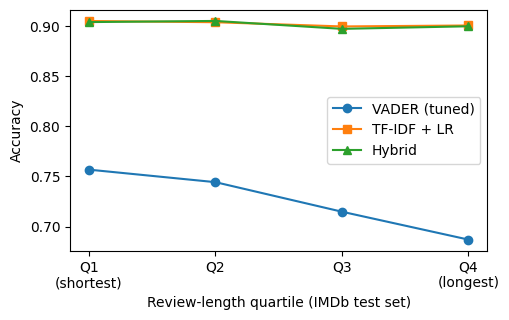

In [16]:
lengths = X_test.str.split().str.len().values
q = pd.qcut(lengths, 4)

acc_len = pd.DataFrame({"length quartile": q,
                        "VADER (tuned)": tuned_pred == y_test,
                        "TF-IDF + LR": lr_pred == y_test,
                        "Hybrid": hyb_pred == y_test}).groupby("length quartile", observed=True).mean()
print(acc_len.round(4))
acc_len.to_csv("outputs/accuracy_by_length.csv")

comp = np.abs(V_test[:, 3])
sat = pd.DataFrame({"length quartile": q, "mean |compound|": comp,
                    "share |compound|>0.9": comp > 0.9}).groupby("length quartile", observed=True).mean()
print(sat.round(3))
sat.to_csv("outputs/vader_saturation_by_length.csv")

plt.figure(figsize=(5.2, 3.3))
xs = np.arange(len(acc_len))
for col, mk in zip(acc_len.columns, ["o", "s", "^"]):
    plt.plot(xs, acc_len[col].values, marker=mk, label=col)
plt.xticks(xs, ["Q1\n(shortest)", "Q2", "Q3", "Q4\n(longest)"])
plt.xlabel("Review-length quartile (IMDb test set)")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/accuracy_by_length.pdf")
plt.show()

In [17]:
rs = np.random.default_rng(SEED)
def show(mask, title, k=5):
    print(f"\n== {title}: {int(mask.sum())} reviews ==")
    for i in rs.choice(np.where(mask)[0], size=k, replace=False):
        print(f"[true={y_test[i]} vader={V_test[i, 3]:+.2f} words={lengths[i]}]",
              repr(X_test.iloc[i][:300]), "\n")

show((tuned_pred != y_test) & (lr_pred == y_test), "VADER wrong, LR right")
show((tuned_pred == y_test) & (lr_pred != y_test), "VADER right, LR wrong")


== VADER wrong, LR right: 5549 reviews ==
[true=1 vader=+0.02 words=121] 'This film is about so many things. Most obvious is the hold that film can have over an audience and how capturing life on film can be a kind of magic. There is also the tense relationship between China and the West as many Chinese saw (probably rightly so) the "Barbarians" as trying to take over and' 

[true=0 vader=+0.89 words=109] "This movie was extremely disappointing, I thought it would be another 'marijuana comedy' but don't be mislead, it's not at all. There are barely any weed-related jokes that come to mind, I don't even think they smoke any weed in this movie. The marijuana field is merely a plot device.<br /><br />My " 

[true=1 vader=+0.79 words=40] "This is a truly great film, with excellent direction. The core plot element, the painting of mila's ass is captivating. I really can't express in words just how much I enjoyed watching Mila getting her ass painted repeatedly.<br /><br />Connor" 

[true=0

In [18]:
if RUN_TRANSFORMER:
    from transformers import pipeline
    import torch
    clf = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english",
                   device=0 if torch.cuda.is_available() else -1)

    def bert_predict(texts, bs=16, chunk=100):
        texts, preds, t0 = list(texts), [], time.time()
        for i in range(0, len(texts), chunk):
            out = clf(texts[i:i + chunk], batch_size=bs, truncation=True, max_length=256)
            preds += [1 if o["label"] == "POSITIVE" else 0 for o in out]
            print(f"{len(preds)}/{len(texts)} done, {time.time() - t0:.0f}s elapsed")
        return np.array(preds)

    N = TRANSFORMER_N
    ri = np.random.default_rng(SEED).choice(len(y_test), N, replace=False)
    ry = np.random.default_rng(SEED).choice(len(y_y1), N, replace=False)
    bi, by = bert_predict(X_test.iloc[ri]), bert_predict(Y1_text.iloc[ry])

    evaluate("Sub IMDb | DistilBERT (SST-2)", y_test[ri], bi)
    evaluate("Sub IMDb | VADER (tuned)", y_test[ri], tuned_pred[ri])
    evaluate("Sub IMDb | TF-IDF + LR", y_test[ri], lr_pred[ri])
    evaluate("Sub IMDb | Hybrid", y_test[ri], hyb_pred[ri])
    evaluate("Sub Yelp-1 | DistilBERT (SST-2)", y_y1[ry], by)
    evaluate("Sub Yelp-1 | VADER (tuned)", y_y1[ry], y1_preds["VADER (tuned)"][ry])
    evaluate("Sub Yelp-1 | TF-IDF + LR", y_y1[ry], y1_preds["TF-IDF + LR (tuned)"][ry])
    evaluate("Sub Yelp-1 | Hybrid", y_y1[ry], y1_preds["Hybrid (feature-level)"][ry])
else:
    print("Transformer reference skipped (RUN_TRANSFORMER = False).")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

100/500 done, 43s elapsed
200/500 done, 86s elapsed
300/500 done, 129s elapsed
400/500 done, 172s elapsed
500/500 done, 215s elapsed
100/500 done, 43s elapsed
200/500 done, 88s elapsed
300/500 done, 130s elapsed
400/500 done, 173s elapsed
500/500 done, 216s elapsed
Sub IMDb | DistilBERT (SST-2)      Accuracy=0.8940  Macro-F1=0.8938
Sub IMDb | VADER (tuned)           Accuracy=0.7440  Macro-F1=0.7439
Sub IMDb | TF-IDF + LR             Accuracy=0.9200  Macro-F1=0.9198
Sub IMDb | Hybrid                  Accuracy=0.9080  Macro-F1=0.9077
Sub Yelp-1 | DistilBERT (SST-2)    Accuracy=0.9160  Macro-F1=0.9160
Sub Yelp-1 | VADER (tuned)         Accuracy=0.7780  Macro-F1=0.7757
Sub Yelp-1 | TF-IDF + LR           Accuracy=0.8500  Macro-F1=0.8477
Sub Yelp-1 | Hybrid                Accuracy=0.9040  Macro-F1=0.9032


## 13. Final tables and figures for the report

                                 Accuracy  Macro-F1
IMDb | Majority class              0.5000    0.3333
IMDb | Random guess                0.5026    0.5026
Yelp-1 | Majority class            0.5016    0.3340
Yelp-1 | Random guess              0.5039    0.5039
IMDb | VADER (threshold 0)         0.6973    0.6886
IMDb | VADER (tuned)               0.7258    0.7257
IMDb | TF-IDF + LR (default)       0.9007    0.9007
IMDb | TF-IDF + LR (tuned)         0.9023    0.9023
IMDb | Hybrid (feature-level)      0.9015    0.9015
IMDb | Hybrid (stacking)           0.9030    0.9030
Yelp-1 | VADER (tuned)             0.7753    0.7748
Yelp-1 | TF-IDF + LR (tuned)       0.8444    0.8438
Yelp-1 | Hybrid (feature-level)    0.8668    0.8664
Yelp-1 | Hybrid (stacking)         0.8455    0.8448
Yelp-2 | VADER (tuned)             0.7719    0.7713
Yelp-2 | TF-IDF + LR (tuned)       0.8458    0.8452
Yelp-2 | Hybrid (feature-level)    0.8665    0.8662
Yelp-2 | Hybrid (stacking)         0.8469    0.8462
Sub IMDb | D

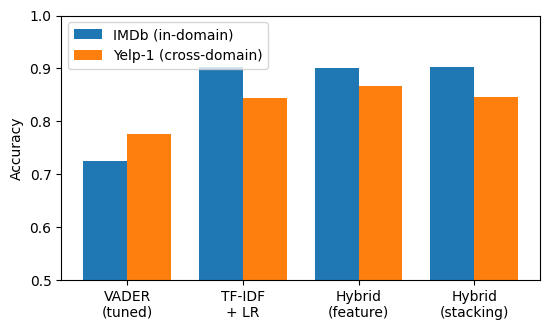


Files in outputs/: ['accuracy_by_length.csv', 'accuracy_by_length.pdf', 'all_results.csv', 'learning_curve.pdf', 'learning_curve_table.csv', 'main_results.pdf', 'mcnemar_results.csv', 'vader_imdb_test.npy', 'vader_imdb_train.npy', 'vader_saturation_by_length.csv', 'vader_threshold.pdf', 'vader_yelp1.npy', 'vader_yelp2.npy', 'weight_sweep_full.csv', 'weight_sweep_small_n.csv']


In [19]:
res = pd.DataFrame(results).T.round(4)
res.to_csv("outputs/all_results.csv")
print(res.to_string())


names = ["VADER (tuned)", "TF-IDF + LR (tuned)", "Hybrid (feature-level)", "Hybrid (stacking)"]
imdb_acc = [results["IMDb | " + n]["Accuracy"] for n in names]
yelp_acc = [results["Yelp-1 | " + n]["Accuracy"] for n in names]
x = np.arange(len(names)); wdt = 0.38
plt.figure(figsize=(5.6, 3.4))
plt.bar(x - wdt / 2, imdb_acc, wdt, label="IMDb (in-domain)")
plt.bar(x + wdt / 2, yelp_acc, wdt, label="Yelp-1 (cross-domain)")
plt.xticks(x, ["VADER\n(tuned)", "TF-IDF\n+ LR", "Hybrid\n(feature)", "Hybrid\n(stacking)"])
plt.ylabel("Accuracy"); plt.ylim(0.5, 1.0)
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("outputs/main_results.pdf")
plt.show()

print("\nFiles in outputs/:", sorted(os.listdir("outputs")))